# 03 Views
Goal: a rule that turns view rows into W, the watch fraction used by every metric.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "../data/ContentWiseImpressions/data/ContentWiseImpressions/CW10M"
inter = pd.read_parquet(f"{ROOT}/interactions").reset_index()
inter["t"] = pd.to_datetime(inter.utc_ts_milliseconds, unit="ms")
views = inter[inter.interaction_type == 0].sort_values(["user_id", "item_id", "t"])

### 3.1 One row or two per view?
**Question:** How many view rows does a (user, item) pair have, and how far apart are they?

**Prediction:** 

In [2]:
views.groupby(['user_id', 'item_id']).size().value_counts().head(10)

1     2239678
2      578800
3      225535
4       89144
5       47640
6       26222
7       17726
8       11756
9        8766
10       6756
Name: count, dtype: int64

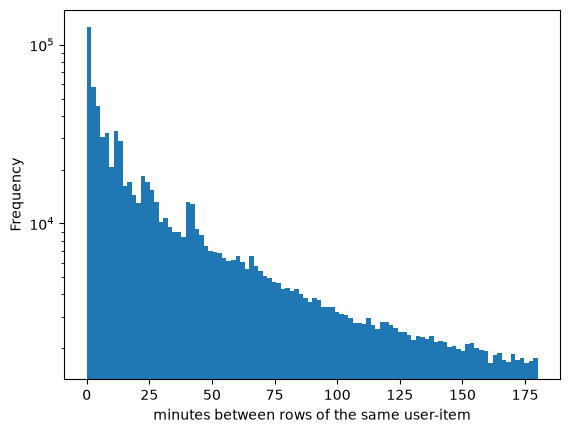

In [3]:
gap = views.groupby(['user_id', 'item_id']).t.diff().dt.total_seconds() / 60
gap.plot.hist(bins=100, range=(0, 180), logy=True, xlabel='minutes between rows of the same user-item')
plt.show()

**Observation:** 

**Decision:** 

### 3.2 vision_factor distribution
**Question:** What does watch fraction look like? Bimodal (sampled vs finished)? Different for films and episodes?

**Prediction:** 

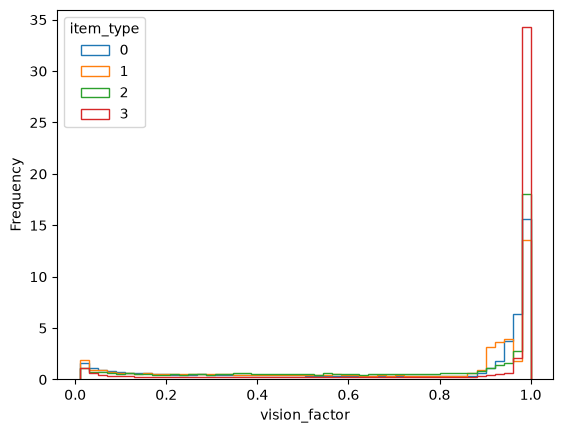

In [4]:
for t, d in views.groupby('item_type'):
    d.vision_factor.plot.hist(bins=50, histtype='step', density=True, label=t)
plt.legend(title='item_type')
plt.xlabel('vision_factor')
plt.show()

**Observation:** 

**Decision:** 

### 3.3 Accounts stuck at 1.0
**Question:** How many accounts have only vision_factor == 1.0, and how much of all viewing do they carry?

**Prediction:** 

In [5]:
share_one = views.groupby('user_id').vision_factor.apply(lambda v: (v == 1).mean())
(share_one == 1).mean(), views.user_id.isin(share_one[share_one == 1].index).mean()

(np.float64(0.027518800559865254), np.float64(0.0005957101356477878))

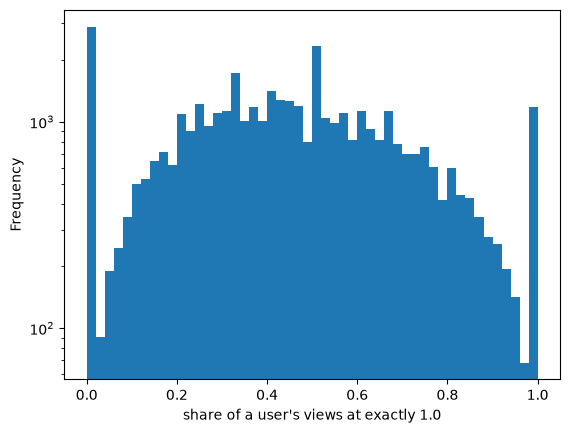

In [6]:
share_one.plot.hist(bins=50, logy=True, xlabel='share of a user\'s views at exactly 1.0')
plt.show()

**Observation:** 

**Decision:** 

### 3.4 Episodes to series
**Question:** When someone watches a series, how many episodes do they watch?

**Prediction:** 

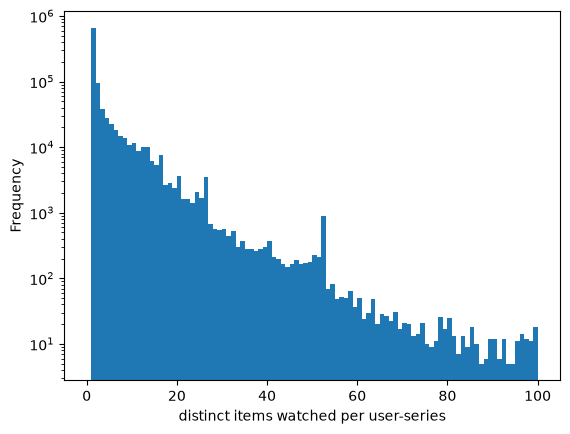

In [7]:
eps = views.groupby(['user_id', 'series_id']).item_id.nunique()
eps.plot.hist(bins=100, range=(0, 100), logy=True, xlabel='distinct items watched per user-series')
plt.show()

**Observation:** 

**Decision:** 

## Decision for this notebook
_The rule for W: which view row counts, and how episodes combine into a series-level W._